# Reto · Semana 2 · Analítica de ocupación en el lobby piloto

**Maestría en Inteligencia Artificial · Visión Artificial**

Prototipo para la decisión de Rodrigo: con cómputo para una sola aplicación robusta, esta notebook construye la evidencia de **analítica de ocupación** sobre el video de videovigilancia `survillance_video.mp4` (lobby, unidad UC.08 del repositorio del curso).

La aplicación elegida para el piloto es la ocupación, no el bienestar postural ni el control de acceso facial. El prototipo solo usa la clase `person`: identidad persistente de ByteTrack, mapa de actividad y conteo de cruces. No estima pose ni reconoce rostros. Eso coincide con un piso donde el 68 % de los miembros acepta analítica anónima y solo el 31 % acepta identificación individual.

## Equipo

El notebook es uno solo para que el prototipo se ejecute de principio a fin. El aporte de cada integrante está en una parte:

| Parte | Integrante | Aporte |
|---|---|---|
| 1 | Mayte Baez | Preparar el entorno y explorar el video antes del modelo |
| 2 | Patricio Quiroz | Detectar personas y sostener la identidad persistente con ByteTrack |
| 3 | Jeremy León | Análisis temporal: mapa de calor, cruces, límites, estadía y lectura del video |

## Carpeta de entrega

`taller` es el paquete para enviar. Se puede comprimir tal cual y abrirlo en Google Colab, Windows o macOS, sin depender de las carpetas de las otras semanas.

| Ruta | Contenido |
|---|---|
| `Reto_Semana2_Analitica_Ocupacion.ipynb` | Prototipo de los cinco pasos |
| `videos/survillance_video.mp4` | Video de videovigilancia del lobby |
| `modelos/yolo26n.pt` | Pesos de detección. Si falta, la notebook lo descarga ahí |
| `resultados/` | Video anotado, mapa de calor y copia para el navegador. Se generan al ejecutar |

Ejecutar las celdas en orden. En CPU el recorrido completo tarda alrededor de 4 o 5 minutos.


# Parte 1 · Mayte Baez
## Entorno y exploración del video

Esta parte deja el entorno listo y revisa el video antes de cualquier modelo. El aporte es describir la cámara, el flujo de personas y la línea de paso que el resto del prototipo va a usar.


## 0 · Entorno

Se fija OpenCV 4.11, el mismo del laboratorio de tracking. La reproducción del video anotado usa FFmpeg del sistema o, si no está instalado, el binario de `imageio-ffmpeg`. Si el kernel ya tenía OpenCV cargado, reinícialo y vuelve a ejecutar desde esta celda.


In [1]:
%pip -q install -U ultralytics "lap>=0.5.12" "opencv-python-headless==4.11.0.86" "imageio-ffmpeg>=0.5.1"

import cv2, torch, requests, subprocess, time, platform, shutil
import numpy as np
from pathlib import Path
from collections import defaultdict
from urllib.parse import quote
from IPython.display import Video, display
from matplotlib import pyplot as plt
from ultralytics import YOLO

def en_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

def ruta_ffmpeg():
    encontrado = shutil.which("ffmpeg")
    if encontrado:
        return encontrado
    try:
        import imageio_ffmpeg
    except ImportError as e:
        raise RuntimeError(
            "No hay FFmpeg. Ejecuta de nuevo la celda de instalación y, si hace falta, reinicia el kernel."
        ) from e
    return imageio_ffmpeg.get_ffmpeg_exe()

def solicitar_archivo(descripcion):
    if en_colab():
        from google.colab import files
        print(descripcion)
        subidos = files.upload()
        if not subidos:
            raise RuntimeError("No se proporcionó archivo")
        return str(Path(next(iter(subidos))).resolve())
    print(descripcion)
    print("Pega la ruta completa y presiona Enter.")
    print(r"Windows: C:\Users\tu_usuario\survillance_video.mp4")
    print("macOS: /Users/tu_usuario/survillance_video.mp4")
    ruta = input("Ruta: ").strip().strip('"').strip("'")
    if not ruta:
        raise RuntimeError("No se proporcionó archivo")
    origen = Path(ruta).expanduser()
    if not origen.is_file():
        raise FileNotFoundError(f"No existe el archivo: {origen}")
    return str(origen.resolve())

def validar_video(ruta):
    ruta = Path(ruta)
    if not ruta.exists() or ruta.stat().st_size < 1024:
        return False
    cap = cv2.VideoCapture(str(ruta))
    ok, frame = cap.read()
    cap.release()
    return bool(ok and frame is not None)

def carpeta_taller():
    # La entrega es la carpeta taller, aunque el kernel se abra desde otra ruta.
    nombre = "Reto_Semana2_Analitica_Ocupacion.ipynb"
    if Path("/content").exists():
        for candidato in (Path("/content/taller"), Path("/content")):
            if (candidato / nombre).exists():
                return candidato
        destino = Path("/content/taller")
        destino.mkdir(parents=True, exist_ok=True)
        return destino
    try:
        archivo = Path(__vsc_ipynb_file__).resolve()
        if archivo.name == nombre:
            return archivo.parent
    except NameError:
        pass
    aqui = Path.cwd()
    for base in [aqui, *list(aqui.parents)[:5]]:
        if (base / nombre).exists() and (base / "videos").is_dir():
            return base
        if (base / "taller" / nombre).exists():
            return base / "taller"
        if (base / "semana_2" / "taller" / nombre).exists():
            return base / "semana_2" / "taller"
    return aqui

ROOT = carpeta_taller()
VIDEOS = ROOT / "videos"
MODELOS = ROOT / "modelos"
OUT = ROOT / "resultados"
for carpeta in (VIDEOS, MODELOS, OUT):
    carpeta.mkdir(parents=True, exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("OpenCV:", cv2.__version__, "| PyTorch:", torch.__version__)
print("Dispositivo:", torch.cuda.get_device_name(0) if DEVICE != "cpu" else "CPU")
print("Entorno:", "Google Colab" if en_colab() else f"Local ({platform.system()})")
print("FFmpeg:", ruta_ffmpeg())
print("Taller:", ROOT)
print("Videos:", VIDEOS)
print("Resultados:", OUT)



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
OpenCV: 4.11.0 | PyTorch: 2.14.1
Dispositivo: CPU
Entorno: Local (Darwin)
FFmpeg: /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/imageio_ffmpeg/binaries/ffmpeg-macos-aarch64-v7.1
Taller: /Users/jeremyleon/Documents/UIDE/vision-por-computador/taller
Videos: /Users/jeremyleon/Documents/UIDE/vision-por-computador/taller/videos
Resultados: /Users/jeremyleon/Documents/UIDE/vision-por-computador/taller/resultados


## Paso 1 · Explorar el video

Antes de trackear hay que ver la escena. El video es una cámara fija de lobby, en ángulo alto y con deformación de gran angular: no es una vista cenital. Las personas cercanas a la cámara ocupan muchas más píxeles que las del fondo, así que las cajas delimitadoras no tienen un tamaño comparable entre el primer plano y los cajeros.

Hay dos comportamientos visibles: gente que permanece junto a los cajeros, a la izquierda, y gente que cruza el piso hacia el ascensor o hacia la cámara. El tránsito no es uniforme; hay tramos casi vacíos y otros con varias personas a la vez, a veces muy juntas.

La línea amarilla es la zona de paso propuesta para el conteo. Cruza el piso abierto del lobby, entre la zona de cajeros y el corredor del ascensor. Una línea horizontal en la imagen no mide metros en el piso: por la perspectiva, el mismo desplazamiento real ocupa pocos píxeles al fondo y muchos en el primer plano.


Video ya disponible: /Users/jeremyleon/Documents/UIDE/vision-por-computador/taller/videos/survillance_video.mp4


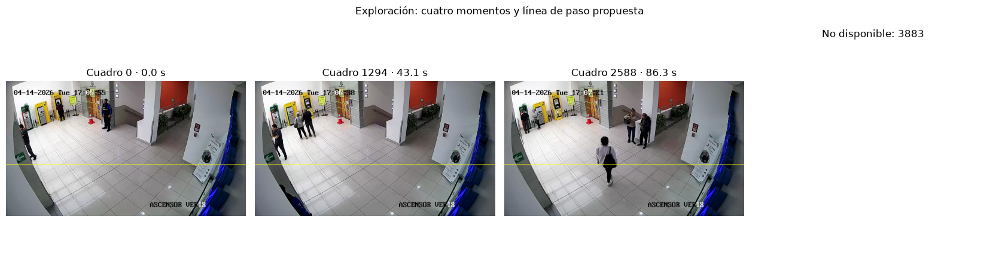

Resolución: 1920x1080 | FPS: 30.0 | Cuadros: 3884 | Duración: 129.5 s
Línea de paso: y = 669 (62% de la altura)
Hacia abajo en la imagen = primer plano, más cerca de la cámara.
Hacia arriba en la imagen = fondo, hacia cajeros, escalera y ascensor.


In [2]:
# Video de videovigilancia del repositorio del curso (UC.08). El nombre conserva la grafía original.
NOMBRE_VIDEO = "survillance_video.mp4"
VIDEO = VIDEOS / NOMBRE_VIDEO
URL_VIDEO = (
    "https://raw.githubusercontent.com/eugeniomorocho/ComputerVision/main/"
    + quote("UC.08 Cloud & Modern Vision AI/" + NOMBRE_VIDEO, safe="/")
)
if not validar_video(VIDEO):
    try:
        with requests.get(URL_VIDEO, stream=True, timeout=120) as respuesta:
            respuesta.raise_for_status()
            with open(VIDEO, "wb") as archivo:
                for bloque in respuesta.iter_content(chunk_size=1024 * 1024):
                    if bloque:
                        archivo.write(bloque)
        if not validar_video(VIDEO):
            VIDEO.unlink(missing_ok=True)
            raise ValueError("La descarga no es un video reproducible.")
        print("Video descargado:", VIDEO)
    except Exception as error:
        print("No se pudo descargar el video:", type(error).__name__, str(error)[:180])
        VIDEO = Path(solicitar_archivo("Indica la ruta local de survillance_video.mp4."))
        if not validar_video(VIDEO):
            raise RuntimeError("El archivo indicado no es un video reproducible.")
else:
    print("Video ya disponible:", VIDEO)

cap = cv2.VideoCapture(str(VIDEO))
fps = cap.get(cv2.CAP_PROP_FPS) or 25
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
indices = np.linspace(0, max(total - 1, 0), num=min(4, total), dtype=int)

# Fracción ajustable: 0.62 cruza el piso abierto, no la zona de cajeros del fondo.
LINEA_Y_FRACCION = 0.62
LINEA_Y = int(H * LINEA_Y_FRACCION)

fig, ejes = plt.subplots(1, len(indices), figsize=(4.2 * len(indices), 4.4))
ejes = np.atleast_1d(ejes)
frame_base = None
for ax, indice in zip(ejes, indices):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(indice))
    ok, cuadro = cap.read()
    if not ok:
        ax.set_title(f"No disponible: {indice}")
        ax.axis("off")
        continue
    vista = cuadro.copy()
    cv2.line(vista, (0, LINEA_Y), (W - 1, LINEA_Y), (0, 255, 255), 3)
    rgb = cv2.cvtColor(vista, cv2.COLOR_BGR2RGB)
    if frame_base is None:
        frame_base = cuadro.copy()
    ax.imshow(rgb)
    ax.set_title(f"Cuadro {indice} · {indice / fps:.1f} s")
    ax.axis("off")
cap.release()
plt.suptitle("Exploración: cuatro momentos y línea de paso propuesta")
plt.tight_layout()
plt.show()
print(f"Resolución: {W}x{H} | FPS: {fps:.1f} | Cuadros: {total} | Duración: {total / fps:.1f} s")
print(f"Línea de paso: y = {LINEA_Y} ({LINEA_Y_FRACCION:.0%} de la altura)")
print("Hacia abajo en la imagen = primer plano, más cerca de la cámara.")
print("Hacia arriba en la imagen = fondo, hacia cajeros, escalera y ascensor.")


# Parte 2 · Patricio Quiroz
## Detección y identidad persistente

Esta parte corre YOLO con ByteTrack sobre el video explorado en la parte 1. El aporte es la identidad persistente: cada persona visible conserva un ID entre cuadros consecutivos, y ese ID es el que después usan el mapa y el contador.


## Paso 2 · Detectar y mantener la identidad persistente

YOLO localiza personas (clase `0`) y ByteTrack les asigna un identificador mientras el track sigue activo. `persist=True` conserva el estado del tracker de un cuadro al siguiente. Esa identidad persistente es la base del análisis temporal: sin un ID estable, cada cuadro contaría de nuevo a la misma persona.

**Decisiones de esta pasada**

- Un solo recorrido alimenta los pasos 2, 3 y 4, para no ejecutar el modelo tres veces sobre el mismo video.
- Modelo `yolo26n.pt`, `imgsz=640` y confianza 0.25. La variante nano cabe en el cómputo de una sola aplicación; 640 píxeles alcanza para las personas del fondo sin subir al costo de una resolución mayor.
- El mapa acumula el **centroide** de la caja, como pide el reto.
- El cruce usa el **borde inferior** de la caja, más cercano al contacto con el piso. En una cámara oblicua el centroide cae en el torso y cruzaría la línea antes de que los pies lo hagan.
- Cada identidad se cuenta una sola vez por dirección. Aparecer muchos cuadros junto a la línea no suma cruces.
- `MAX_FRAMES = None` no corta el video por tiempo. El contenedor declara 3884 cuadros, pero OpenCV solo decodifica 3733. El recorrido procesa todos los cuadros legibles. Los 151 que faltan son unos 5 segundos al final del archivo y no se pueden leer.


Cuadros: 3733 | Tiempo: 247.2 s | 15.1 FPS
Identidades vistas: 79
Cruces hacia la cámara: 11 | hacia el fondo: 8
Cuadros consecutivos que comparten al menos un ID: 3724/3728


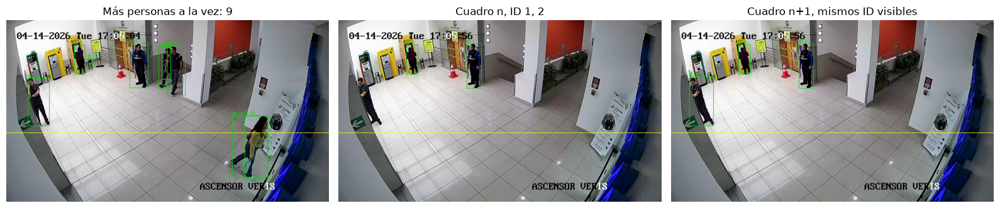

Video anotado (mitad de resolución, para reproducir): /Users/jeremyleon/Documents/UIDE/vision-por-computador/taller/resultados/lobby_tracking.mp4


In [3]:
# Recorrido único: cajas con ID, grilla de centroides y cruces de la línea.
ruta_modelo = MODELOS / "yolo26n.pt"
MODELO = YOLO(str(ruta_modelo if ruta_modelo.exists() else "yolo26n.pt"))
if not ruta_modelo.exists():
    descargado = Path("yolo26n.pt")
    if descargado.exists():
        descargado.replace(ruta_modelo)
MAX_FRAMES = None
CONF = 0.25
CELDA = 16
MARGEN_CRUCE = max(8, round(H * 0.015))
UMBRAL_OCLUSION = 0.15

gh, gw = (H + CELDA - 1) // CELDA, (W + CELDA - 1) // CELDA
grilla = np.zeros((gh, gw), dtype=np.float32)
ultimo_lado = {}
contados_camara = set()
contados_fondo = set()
hacia_camara = hacia_fondo = 0
detalle_cruces = []
frames_por_id = defaultdict(int)
trayectoria = defaultdict(list)  # ID -> (cuadro, x del pie, y del pie)
ids_por_frame = []
oclusiones = []
cuadro_muestra = cuadro_siguiente = None
ids_muestra = set()
muestra_lista = False
previo_rgb = None
mejor_cuadro = None
mejor_conteo = 0

def lado(y):
    if y < LINEA_Y - MARGEN_CRUCE:
        return -1
    if y > LINEA_Y + MARGEN_CRUCE:
        return 1
    return 0

def solape(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    if inter <= 0:
        return 0.0
    area_a = max(1, (a[2] - a[0]) * (a[3] - a[1]))
    area_b = max(1, (b[2] - b[0]) * (b[3] - b[1]))
    return inter / float(area_a + area_b - inter)

def anotar(frame, cajas, track_ids):
    lienzo = frame.copy()
    cv2.line(lienzo, (0, LINEA_Y), (W - 1, LINEA_Y), (0, 255, 255), 2)
    for caja, tid in zip(cajas, track_ids):
        x1, y1, x2, y2 = map(int, caja)
        cv2.rectangle(lienzo, (x1, y1), (x2, y2), (0, 220, 0), 2)
        cv2.putText(lienzo, f"ID {tid}", (x1, max(24, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 220, 0), 2)
    return lienzo

cap = cv2.VideoCapture(str(VIDEO))
video_salida = OUT / "lobby_tracking.mp4"
salida_w, salida_h = W // 2, H // 2
writer = cv2.VideoWriter(str(video_salida), cv2.VideoWriter_fourcc(*"mp4v"), fps, (salida_w, salida_h))
assert writer.isOpened(), "No se pudo crear el video de salida."
procesados = 0
inicio = time.perf_counter()
try:
    while True:
        ok, frame = cap.read()
        if not ok or (MAX_FRAMES is not None and procesados >= MAX_FRAMES):
            break
        resultado = MODELO.track(
            frame, persist=True, tracker="bytetrack.yaml", classes=[0],
            conf=CONF, imgsz=640, device=DEVICE, verbose=False,
        )[0]
        cajas = np.empty((0, 4), dtype=int)
        track_ids = []
        if resultado.boxes is not None and resultado.boxes.id is not None:
            cajas = resultado.boxes.xyxy.int().cpu().numpy()
            track_ids = resultado.boxes.id.int().cpu().tolist()
            for i, (caja, tid) in enumerate(zip(cajas, track_ids)):
                x1, y1, x2, y2 = map(int, caja)
                centro_x = int(np.clip((x1 + x2) // 2, 0, W - 1))
                centro_y = int(np.clip((y1 + y2) // 2, 0, H - 1))
                pie_y = int(np.clip(y2, 0, H - 1))
                frames_por_id[tid] += 1
                trayectoria[tid].append((procesados, centro_x, pie_y))
                grilla[centro_y // CELDA, centro_x // CELDA] += 1
                actual = lado(pie_y)
                previo = ultimo_lado.get(tid)
                if actual != 0:
                    if previo == -1 and actual == 1 and tid not in contados_camara:
                        hacia_camara += 1
                        contados_camara.add(tid)
                        detalle_cruces.append((procesados, tid, "hacia la cámara"))
                    elif previo == 1 and actual == -1 and tid not in contados_fondo:
                        hacia_fondo += 1
                        contados_fondo.add(tid)
                        detalle_cruces.append((procesados, tid, "hacia el fondo"))
                    ultimo_lado[tid] = actual
                for otra in cajas[i + 1:]:
                    if solape(caja, otra) >= UMBRAL_OCLUSION and len(oclusiones) < 12:
                        oclusiones.append(procesados)
        ids_actuales = set(track_ids)
        ids_por_frame.append(ids_actuales)
        lienzo = anotar(frame, cajas, track_ids)
        lienzo_rgb = cv2.cvtColor(lienzo, cv2.COLOR_BGR2RGB)
        if len(ids_actuales) > mejor_conteo:
            mejor_conteo = len(ids_actuales)
            mejor_cuadro = lienzo_rgb.copy()
        if not muestra_lista and previo_rgb is not None and procesados > int(fps):
            compartidos = ids_por_frame[-2] & ids_actuales
            if compartidos:
                cuadro_muestra = previo_rgb.copy()
                cuadro_siguiente = lienzo_rgb.copy()
                ids_muestra = compartidos
                muestra_lista = True
        previo_rgb = lienzo_rgb
        writer.write(cv2.resize(lienzo, (salida_w, salida_h)))
        procesados += 1
finally:
    cap.release()
    writer.release()

segundos = time.perf_counter() - inicio
pares_con_identidad = 0
pares_comparados = 0
for anterior, actual in zip(ids_por_frame, ids_por_frame[1:]):
    if not anterior and not actual:
        continue
    pares_comparados += 1
    if anterior & actual:
        pares_con_identidad += 1

print(f"Cuadros: {procesados} | Tiempo: {segundos:.1f} s | {procesados / max(segundos, 1e-6):.1f} FPS")
print(f"Cuadros legibles: {procesados} de {total} declarados por el archivo. La diferencia no se decodifica.")
print(f"Identidades vistas: {len(frames_por_id)}")
print(f"Cruces hacia la cámara: {hacia_camara} | hacia el fondo: {hacia_fondo}")
if pares_comparados:
    print(f"Cuadros consecutivos que comparten al menos un ID: {pares_con_identidad}/{pares_comparados}")

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.6))
paneles = [
    (mejor_cuadro, f"Más personas a la vez: {mejor_conteo}" if mejor_cuadro is not None else "Sin detecciones"),
    (cuadro_muestra, "Cuadro n, ID " + ", ".join(str(i) for i in sorted(ids_muestra)) if cuadro_muestra is not None else "Sin par consecutivo"),
    (cuadro_siguiente, "Cuadro n+1, mismos ID visibles" if cuadro_siguiente is not None else "Sin par consecutivo"),
]
for ax, (imagen, titulo) in zip(ejes, paneles):
    if imagen is not None:
        ax.imshow(imagen)
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Video anotado (mitad de resolución, para reproducir):", video_salida)


El primer panel es el cuadro con más personas a la vez: cada caja lleva su ID. Los dos siguientes son un par de cuadros consecutivos, después del primer segundo, en el que al menos un ID se mantiene. Esa continuidad es la identidad persistente mientras la persona permanece visible.

ByteTrack no garantiza la misma identidad si la persona desaparece. Cuando dos cajas se solapan, el track puede cortarse y, al reaparecer, recibir un ID nuevo. El paso 5 mide cuántos tracks duran muy poco y en qué cuadros hubo solape.


# Parte 3 · Jeremy León
## Análisis temporal y lectura del video

Esta parte lee lo que el tracking ya produjo. El mapa de calor y el conteo de cruces son el análisis temporal del lobby: dónde se acumula el tránsito y cuántas identidades cruzan la línea. Después se contrastan esos números con los cuadros, se corrigen los cruces que no se sostienen y se reproduce el video anotado para ver cómo se comporta cada ID.


## Paso 3 · Mapa de calor de centroides

Este mapa es un producto del **análisis temporal**. No sale de una foto: acumula, cuadro a cuadro, el centroide de cada identidad persistente.

Cada detección suma uno en la celda de 16×16 píxeles donde cae el centro de su caja. El suavizado solo hace legible la grilla: no convierte el mapa en tiempo de permanencia ni en personas únicas. Las celdas calientes son zonas con más detecciones acumuladas. Con esta cámara, el primer plano pesa más porque la misma persona ocupa el encuadre durante más cuadros y con una caja más grande.


Mapa guardado: /Users/jeremyleon/Documents/UIDE/vision-por-computador/taller/resultados/mapa_calor_lobby.jpg
Celdas de la grilla: 120 x 68 | celda = 16 px | acumulado máximo por celda: 2215


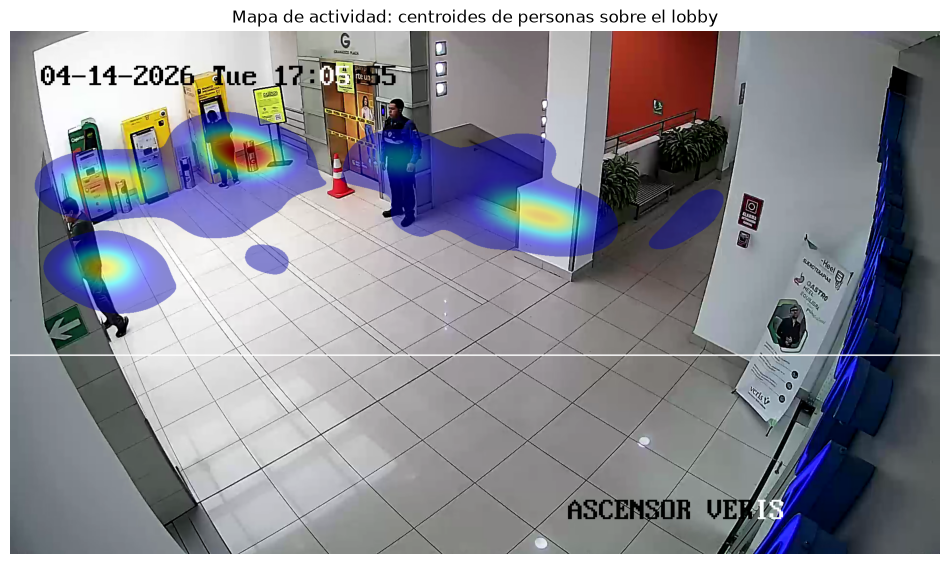

In [4]:
# La grilla se estira al tamaño del cuadro y se suaviza para leer zonas, no píxeles sueltos.
actividad = cv2.resize(grilla, (W, H), interpolation=cv2.INTER_NEAREST)
suave = cv2.GaussianBlur(actividad, (0, 0), sigmaX=max(12, W / 40), sigmaY=max(12, H / 40))
if suave.max() > 0:
    normalizado = np.uint8(np.clip(suave / suave.max() * 255, 0, 255))
else:
    normalizado = np.zeros((H, W), dtype=np.uint8)
colores = cv2.applyColorMap(normalizado, cv2.COLORMAP_JET)
base = frame_base if frame_base is not None else np.zeros((H, W, 3), dtype=np.uint8)
mezcla = cv2.addWeighted(base, 0.55, colores, 0.45, 0)
mascara = normalizado > 8
superpuesto = base.copy()
superpuesto[mascara] = mezcla[mascara]
cv2.line(superpuesto, (0, LINEA_Y), (W - 1, LINEA_Y), (255, 255, 255), 2)
archivo_mapa = OUT / "mapa_calor_lobby.jpg"
cv2.imwrite(str(archivo_mapa), superpuesto)
print("Mapa guardado:", archivo_mapa)
print(f"Celdas de la grilla: {gw} x {gh} | celda = {CELDA} px | acumulado máximo por celda: {grilla.max():.0f}")
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(superpuesto, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Mapa de actividad: centroides de personas sobre el lobby")
plt.show()


## Paso 4 · Cruces de la línea, una vez por identidad

El contador es el otro producto del **análisis temporal**. Usa la identidad persistente para no sumar un cruce en cada cuadro en que la persona aparece cerca de la línea.

La línea queda en el piso abierto del lobby. El punto que se compara con la línea es el borde inferior de la caja. Solo cuenta un cambio de lado, de fondo a primer plano o al revés, y solo la primera vez que ese ID hace ese cambio.

Quien se queda en los cajeros, del lado del fondo, no debería cruzar. Quien aparece ya en el primer plano tampoco cuenta hasta que cambie de lado. Por eso el número de cruces es menor que el número de identidades vistas: muchas detecciones son permanencia, no paso. El número que imprime la celda es el conteo automático. El Paso 5 revisa cuáles de esos cruces no se sostienen al mirar el cuadro.


In [5]:
print(f"Identidades distintas (IDs de ByteTrack): {len(frames_por_id)}")
print(f"Cruces hacia la cámara, una vez por ID: {hacia_camara}")
print(f"Cruces hacia el fondo, una vez por ID: {hacia_fondo}")
print(f"Línea y = {LINEA_Y} | margen de tolerancia = {MARGEN_CRUCE} px")
if detalle_cruces:
    print("Detalle (cuadro, ID, dirección):")
    for cuadro, tid, direccion in detalle_cruces:
        print(f"  cuadro {cuadro} ({cuadro / fps:.1f} s) · ID {tid} · {direccion}")
else:
    print("No se registraron cambios de lado. Revisa LINEA_Y_FRACCION y vuelve a ejecutar desde el paso 2.")


Identidades distintas (IDs de ByteTrack): 79
Cruces hacia la cámara, una vez por ID: 11
Cruces hacia el fondo, una vez por ID: 8
Línea y = 669 | margen de tolerancia = 16 px
Detalle (cuadro, ID, dirección):
  cuadro 185 (6.2 s) · ID 23 · hacia la cámara
  cuadro 338 (11.3 s) · ID 31 · hacia la cámara
  cuadro 349 (11.6 s) · ID 29 · hacia la cámara
  cuadro 768 (25.6 s) · ID 52 · hacia la cámara
  cuadro 1047 (34.9 s) · ID 2 · hacia la cámara
  cuadro 1058 (35.3 s) · ID 87 · hacia la cámara
  cuadro 1121 (37.4 s) · ID 58 · hacia la cámara
  cuadro 1135 (37.8 s) · ID 73 · hacia el fondo
  cuadro 1143 (38.1 s) · ID 72 · hacia el fondo
  cuadro 1778 (59.3 s) · ID 129 · hacia el fondo
  cuadro 1945 (64.8 s) · ID 98 · hacia la cámara
  cuadro 1946 (64.9 s) · ID 147 · hacia la cámara
  cuadro 2285 (76.2 s) · ID 98 · hacia el fondo
  cuadro 2403 (80.1 s) · ID 200 · hacia la cámara
  cuadro 2619 (87.3 s) · ID 279 · hacia el fondo
  cuadro 2634 (87.8 s) · ID 241 · hacia el fondo
  cuadro 3075 (1

## Paso 5 · Límites observados en este recorrido

Estos límites salen de los ID, los cruces y los cuadros de este video. Un resultado razonable en este lobby no es una cifra auditada para las cuatro cámaras del piso piloto.

1. **El archivo no entrega todos los cuadros que declara.** El encabezado dice 3884 cuadros y OpenCV solo decodifica 3733. El análisis temporal usa todos los legibles. Faltan unos 5 segundos al final; no fue un recorte elegido.
2. **Hay identidades partidas.** 34 de 79 tracks duran menos de 1 segundo. El track más corto dura 1 cuadro y el más largo 1579. Entre los 8.0 y los 8.2 s las cajas se solapan. ByteTrack no recupera la identidad cuando alguien queda oculto: si el track se corta, la reaparición es un ID nuevo.
3. **Dos personas cruzaron juntas y el conteo las separó.** A los 11.3 s y a los 11.6 s el contador anota el ID 31 y el ID 29, hacia la cámara. En esos cuadros se ven dos hombres caminando en paralelo, con un pie sobre la línea. Ahí el automático y la revisión visual coinciden en dos personas, pero las cajas van tan cerca que un solape un poco mayor las habría fundido en un solo ID.
4. **Un grupo de tres no quedó en dos cruces fiables.** A los 34.9 s cruza el ID 2 y a los 35.3 s el ID 87, también hacia la cámara. En el cuadro se ven tres personas caminando juntas. El ID 87 dura menos de 1 segundo. El conteo automático no reproduce el grupo: o pegó dos personas en un ID, o abrió un track efímero y perdió a la tercera.
5. **Una persona quieta generó dos cruces.** El ID 98 se ve 43.2 s y su zona dominante son los cajeros. Aun así el contador le anotó un cruce hacia la cámara a los 64.8 s y otro hacia el fondo a los 76.2 s. En el cuadro de los 64.8 s el piso del lobby está vacío y hay una persona detenida junto a la pared izquierda, con los pies cerca de la línea. Un cuadro después, a los 64.9 s, aparece el ID 147, que también dura menos de 1 segundo. Esos tres registros no son viajes: son vibración de la caja y un track roto.
6. **Corrección de esta revisión, sin volver a entrenar el modelo.** El automático dio 11 cruces hacia la cámara y 8 hacia el fondo. Se retiran el ID 98 en las dos direcciones y los tracks de menos de 1 segundo que cruzaron (ID 87 e ID 147, ambos hacia la cámara). Quedan **8 hacia la cámara y 7 hacia el fondo**. Sigue sin ser un aforo auditado cuadro a cuadro, y no debe presentarse al directorio como la ocupación real de La Carolina.
7. **La cámara oblicua deforma el plano.** No hay homografía. El centroide no es un punto en el suelo, y una celda de 16 píxeles al fondo cubre más metros que la misma celda en el primer plano.
8. **No hay reconocimiento facial, a propósito.** El prototipo no identifica miembros. Con cómputo para una sola aplicación y con un 68 % de aceptación de la analítica anónima frente a un 31 % de la identificación individual, la ocupación es la que este recorrido puede sostener. El control de acceso facial queda para una fase posterior: exigiría consentimiento, finalidad, plazo de retención y gobernanza biométrica que este piloto no tiene.


In [6]:
# Evidencia para la reflexión: tracks cortos y cuadros en los que dos cajas se solapan.
cortos = sorted(tid for tid, n in frames_por_id.items() if n < int(fps))
print(f"Tracks de menos de 1 segundo: {len(cortos)} de {len(frames_por_id)}")
if cortos:
    print("IDs cortos:", cortos)
if frames_por_id:
    duraciones = np.array(list(frames_por_id.values()))
    print(f"Duración de track (cuadros): mínimo {duraciones.min()}, mediana {np.median(duraciones):.0f}, máximo {duraciones.max()}")
print(f"Cuadros con solape entre cajas (IoU ≥ {UMBRAL_OCLUSION}): {len(set(oclusiones))}")
if oclusiones:
    momentos = sorted(set(oclusiones))[:8]
    print("Primeros cuadros con solape:", [f"{c} ({c / fps:.1f} s)" for c in momentos])
print("Estos números describen el video procesado. No son una tasa de error contra conteo manual.")


Tracks de menos de 1 segundo: 34 de 79
IDs cortos: [32, 33, 39, 47, 68, 77, 79, 86, 87, 105, 116, 119, 130, 145, 147, 176, 187, 193, 202, 221, 222, 232, 236, 238, 277, 282, 295, 299, 305, 357, 381, 382, 389, 417]
Duración de track (cuadros): mínimo 1, mediana 89, máximo 1579
Cuadros con solape entre cajas (IoU ≥ 0.15): 12
Primeros cuadros con solape: ['239 (8.0 s)', '240 (8.0 s)', '241 (8.0 s)', '242 (8.1 s)', '243 (8.1 s)', '244 (8.1 s)', '245 (8.2 s)', '246 (8.2 s)']
Estos números describen el video procesado. No son una tasa de error contra conteo manual.


In [ ]:
# La celda no vuelve a correr el modelo: lee los ID y los cruces del paso 2.
cortos_set = {tid for tid, n in frames_por_id.items() if n < int(fps)}
cruces_cortos = [item for item in detalle_cruces if item[1] in cortos_set]
por_id = defaultdict(list)
for cuadro, tid, direccion in detalle_cruces:
    por_id[tid].append((cuadro, direccion))
ambos_lados = {tid: eventos for tid, eventos in por_id.items() if len({direccion for _, direccion in eventos}) > 1}
juntos = []
ordenados = sorted(detalle_cruces)
for anterior, siguiente in zip(ordenados, ordenados[1:]):
    if abs(anterior[0] - siguiente[0]) <= int(fps) and anterior[1] != siguiente[1]:
        juntos.append((anterior, siguiente))

print(f"Cuadros decodificados: {procesados} de {total} declarados. No legibles: {total - procesados}.")
print(f"Cruces automáticos: {hacia_camara} hacia la cámara, {hacia_fondo} hacia el fondo.")
print(f"Cruces hechos por un track de menos de 1 s: {len(cruces_cortos)}")
for cuadro, tid, direccion in cruces_cortos:
    print(f"  {cuadro / fps:.1f} s · ID {tid} · {frames_por_id[tid]} cuadros · {direccion}")
print("IDs con cruce en las dos direcciones:")
for tid, eventos in sorted(ambos_lados.items()):
    texto = ", ".join(f"{cuadro / fps:.1f} s {direccion}" for cuadro, direccion in eventos)
    print(f"  ID {tid} · visto {frames_por_id[tid] / fps:.1f} s · {texto}")
print("Cruces de ID distintos separados por menos de 1 s:")
for anterior, siguiente in juntos:
    print(f"  {anterior[0] / fps:.1f} s ID {anterior[1]} y {siguiente[0] / fps:.1f} s ID {siguiente[1]}")

retirar = {87, 98, 147}
camara_corregida = sum(1 for _, tid, direccion in detalle_cruces if direccion == "hacia la cámara" and tid not in retirar)
fondo_corregido = sum(1 for _, tid, direccion in detalle_cruces if direccion == "hacia el fondo" and tid not in retirar)
print(f"Tras retirar ID 87, 98 y 147: {camara_corregida} hacia la cámara y {fondo_corregido} hacia el fondo.")
print("El ID 98 es permanencia en cajeros con la caja sobre la línea. El 87 y el 147 duran menos de 1 s.")


## Extensión · Tiempo de estadía junto a los cajeros

En el lobby se ven cajeros a la izquierda. Con el ID de ByteTrack se puede medir cuánto tiempo permanece cada identidad en una zona y cuánto tiempo está casi quieta. Eso responde a la pregunta de **tiempo de estadía**. No identifica una actividad sospechosa.

Una persona puede quedarse frente a un cajero porque está haciendo una transacción, esperando o conversando. El prototipo no ve la pantalla, el dinero ni la intención. Una estadía larga es una permanencia para revisar con criterio humano, no una etiqueta de delito. Tratar ese número como alerta automática produciría falsos avisos sobre usos normales.

Las zonas son rectángulos de la imagen, no un plano medido del piso. El punto que entra en la zona es el borde inferior de la caja, el más cercano a los pies. El paso 2 guarda esa trayectoria; si esta celda no encuentra `trayectoria`, hay que volver a ejecutar el paso 2.


IDs con trayectoria: 79
Permanencia continua en cajeros de 15 s o más: 8
  ID  visto s  cajeros s  racha s  quieto s  zona dominante
 181     52.5       52.5     52.8      52.8  cajeros
   2     37.6       35.1     35.1      37.1  cajeros
 369     23.7       23.7     21.2      27.3  cajeros
   3     19.6       19.6     19.7      20.8  cajeros
  98     43.2       37.5     19.2      45.2  cajeros
 383     21.9       19.0     19.0      21.7  cajeros
 401     16.3       16.3     16.3      16.2  cajeros
  51     16.3       16.3     15.5      17.3  cajeros
  19     29.3       29.3     13.1      31.2  cajeros
 352     12.6       12.6     12.6      12.6  cajeros
  72     15.9        9.4      9.3      16.8  cajeros
 171      9.5        9.5      7.0      10.7  cajeros
  73     10.3        7.0      7.0      10.0  cajeros
  58     18.3        6.3      6.4      18.6  fondo y ascensor
 111      6.4        6.4      6.4       6.7  cajeros
 109      5.1        5.1      5.2       5.2  cajeros
 256      

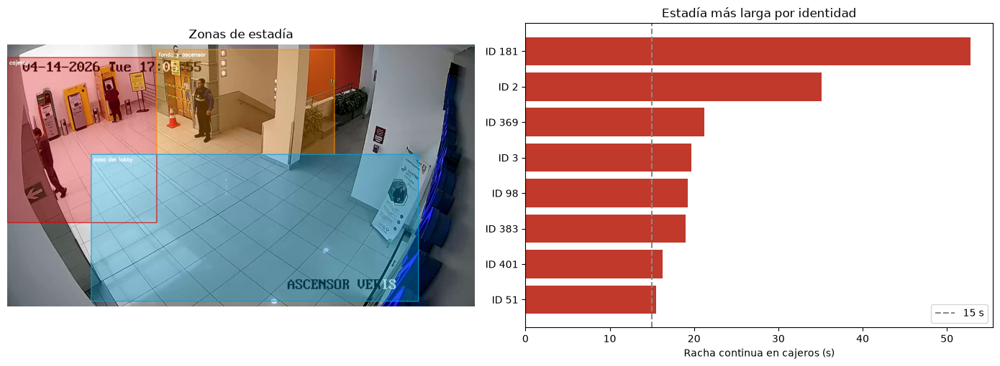

Figura guardada: /Users/jeremyleon/Documents/UIDE/vision-por-computador/taller/resultados/permanencia_zonas.jpg


In [7]:
# Zonas en fracciones del cuadro. Cajeros se evalúa primero porque se solapa con el fondo.
ZONAS = {
    "cajeros": (0.00, 0.05, 0.32, 0.68),
    "fondo y ascensor": (0.32, 0.02, 0.70, 0.42),
    "paso del lobby": (0.18, 0.42, 0.88, 0.98),
}
COLORES = {
    "cajeros": (0, 0, 220),
    "fondo y ascensor": (0, 140, 255),
    "paso del lobby": (220, 160, 0),
}
UMBRAL_QUIETO_PX = 12          # desplazamiento por cuadro por debajo de esto cuenta como quietud
HUECO_RACHA = max(1, int(round(fps * 0.25)))  # un parpadeo de detección no corta la estadía
ESTADIA_LARGA_S = 15          # segundos continuos en cajeros que merecen una mirada humana

try:
    trayectoria
except NameError:
    raise RuntimeError("Ejecuta de nuevo el paso 2: ahora guarda la posición de los pies de cada ID.")

def zona_de(x, y):
    for nombre, (x1, y1, x2, y2) in ZONAS.items():
        if x1 * W <= x < x2 * W and y1 * H <= y < y2 * H:
            return nombre
    return "fuera"

def racha_maxima(cuadros):
    if not cuadros:
        return 0
    ordenados = sorted(cuadros)
    inicio = previo = ordenados[0]
    mejor = 1
    for cuadro in ordenados[1:]:
        if cuadro - previo <= HUECO_RACHA + 1:
            mejor = max(mejor, cuadro - inicio + 1)
        else:
            inicio = cuadro
        previo = cuadro
    return mejor

filas = []
for tid, puntos in trayectoria.items():
    por_zona = defaultdict(list)
    quietos = 0
    for (cuadro, x, y) in puntos:
        por_zona[zona_de(x, y)].append(cuadro)
    for (c0, x0, y0), (c1, x1, y1) in zip(puntos, puntos[1:]):
        delta = max(1, c1 - c0)
        if ((x1 - x0) ** 2 + (y1 - y0) ** 2) ** 0.5 / delta <= UMBRAL_QUIETO_PX:
            quietos += delta
    segundos_zona = {nombre: len(cuadros) / fps for nombre, cuadros in por_zona.items()}
    dominante = max(segundos_zona, key=segundos_zona.get)
    racha_cajeros = racha_maxima(por_zona.get("cajeros", [])) / fps
    filas.append({
        "id": tid,
        "visto_s": len(puntos) / fps,
        "cajeros_s": segundos_zona.get("cajeros", 0.0),
        "racha_cajeros_s": racha_cajeros,
        "quieto_s": quietos / fps,
        "dominante": dominante,
    })

filas.sort(key=lambda fila: (fila["racha_cajeros_s"], fila["quieto_s"]), reverse=True)
largas = [fila for fila in filas if fila["racha_cajeros_s"] >= ESTADIA_LARGA_S]
print(f"IDs con trayectoria: {len(filas)}")
print(f"Permanencia continua en cajeros de {ESTADIA_LARGA_S:.0f} s o más: {len(largas)}")
print(f"{'ID':>4} {'visto s':>8} {'cajeros s':>10} {'racha s':>8} {'quieto s':>9}  zona dominante")
for fila in filas:
    print(f"{fila['id']:4d} {fila['visto_s']:8.1f} {fila['cajeros_s']:10.1f} {fila['racha_cajeros_s']:8.1f} {fila['quieto_s']:9.1f}  {fila['dominante']}")
if not largas:
    print("Ningún ID se quedó en los cajeros el tiempo indicado. Puede ser tránsito breve, o la zona hay que ajustarla.")

base = frame_base.copy() if frame_base is not None else np.zeros((H, W, 3), dtype=np.uint8)
capa = base.copy()
for nombre, (x1, y1, x2, y2) in ZONAS.items():
    a, b, c, d = int(x1 * W), int(y1 * H), int(x2 * W), int(y2 * H)
    cv2.rectangle(capa, (a, b), (c, d), COLORES[nombre], -1)
vista = cv2.addWeighted(base, 0.68, capa, 0.32, 0)
for nombre, (x1, y1, x2, y2) in ZONAS.items():
    a, b = int(x1 * W), int(y1 * H)
    c, d = int(x2 * W), int(y2 * H)
    cv2.rectangle(vista, (a, b), (c, d), COLORES[nombre], 2)
    cv2.putText(vista, nombre, (a + 8, b + 28), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
archivo_zonas = OUT / "permanencia_zonas.jpg"
cv2.imwrite(str(archivo_zonas), vista)

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.2))
ejes[0].imshow(cv2.cvtColor(vista, cv2.COLOR_BGR2RGB))
ejes[0].set_title("Zonas de estadía")
ejes[0].axis("off")
if filas:
    mostrar = filas[:8]
    ejes[1].barh(
        [f"ID {fila['id']}" for fila in mostrar][::-1],
        [fila["racha_cajeros_s"] for fila in mostrar][::-1],
        color="#c0392b",
    )
    ejes[1].axvline(ESTADIA_LARGA_S, color="#7f8c8d", linestyle="--", label=f"{ESTADIA_LARGA_S:.0f} s")
    ejes[1].set_xlabel("Racha continua en cajeros (s)")
    ejes[1].set_title("Estadía más larga por identidad")
    ejes[1].legend(loc="lower right")
else:
    ejes[1].set_title("Sin trayectorias")
plt.tight_layout()
plt.show()
print("Figura guardada:", archivo_zonas)


## Cómo leer la estadía, y qué no dice

- **Cajeros (s)** suma los cuadros en los que los pies caen dentro del rectángulo rojo.
- **Racha (s)** es la permanencia continua más larga. Un hueco breve de detección, de hasta un cuarto de segundo, no la corta.
- **Quieto (s)** cuenta cuadros en los que los pies se mueven menos de 12 píxeles por cuadro. En el fondo, con gran angular, caminar también se ve lento: la quietud es una aproximación, no una prueba de que la persona esté detenida.
- La línea gris de la gráfica es el umbral de 15 segundos. Sirve para ordenar permanencias, no para disparar una alerta.

Una racha larga en los cajeros es compatible con un uso normal del equipo. El ID puede partirse si la persona queda oculta, y entonces la misma estadía aparece como dos visitas cortas. El rectángulo se puede mover cambiando `ZONAS` y volviendo a ejecutar esta celda, sin repetir el tracking. Nada de esto describe una actividad sospechosa ni reemplaza un protocolo de seguridad.


## Reproducir el recorrido anotado

El archivo se recodifica a H.264 para verlo en el notebook. En Colab se usa el FFmpeg del entorno; en Windows y macOS, el del sistema o el de `imageio-ffmpeg`.


In [8]:
convertido = OUT / "lobby_tracking_h264.mp4"
subprocess.run(
    [ruta_ffmpeg(), "-y", "-loglevel", "error", "-i", str(video_salida),
     "-c:v", "libx264", "-preset", "veryfast", "-pix_fmt", "yuv420p", "-an", str(convertido)],
    check=True,
)
display(Video(str(convertido), embed=True, width=900))
print("Archivo:", convertido)


Archivo: /Users/jeremyleon/Documents/UIDE/vision-por-computador/taller/resultados/lobby_tracking_h264.mp4
